In [1]:
#Importing Packages
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [2]:
#Defining the Neural Network models
class Net(nn.Module):
    def __init__(self, n):
        super(Net, self).__init__()
        self.hidden_layer1 = nn.Linear(n,60)
        self.hidden_layer2 = nn.Linear(60,100)
        self.hidden_layer3 = nn.Linear(100,100)
        self.hidden_layer4 = nn.Linear(100,80)
        self.output_layer = nn.Linear(80,50)
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.xavier_normal_(m.weight, gain=nn.init.calculate_gain('tanh'))
            nn.init.zeros_(m.bias)


    def forward(self, inputs):
        layer1_out = torch.tanh(self.hidden_layer1(inputs))
        layer2_out = torch.tanh(self.hidden_layer2(layer1_out))
        layer3_out = torch.tanh(self.hidden_layer3(layer2_out))
        layer4_out = torch.tanh(self.hidden_layer4(layer3_out))
        output = self.output_layer(layer4_out)
        return output

class DeepONet(nn.Module):
    def __init__(self, branch_net, trunk_net):
        super().__init__()
        self.branch_net = branch_net
        self.trunk_net = trunk_net
        self.bias = nn.Parameter(torch.zeros(1))

    def forward(self, branch_input, trunk_input):
        b = self.branch_net(branch_input)  # [N, p]
        t = self.trunk_net(trunk_input)    # [N, p]
        u_pred = torch.sum(b * t, dim=1, keepdim=True)
        return u_pred + self.bias

In [3]:
#Defining Important variables
a = 0.4 #Constant from 1D heat PDE
L = 1 # Length of bar in meters
M = 1 # Max time value in seconds
sensor_num = 51 # Number of points in the ic array

#Creating Net object
branch_net = Net(sensor_num).to(device)
trunk_net = Net(2).to(device)
deep_net = DeepONet(branch_net, trunk_net).to(device)
deep_optimizer = torch.optim.Adam(deep_net.parameters(), lr=0.001)

In [4]:
"""
Finite difference solver for the 1D heat equation using explicit FTCS
(Forward-Time, Centered-Space) finite differences.

Equation solved:
    u_t = alpha * u_xx,   x in [0, L], t in [0, T]
    u(0, t) = u(L, t) = 0                      (fixed zero boundary conditions)
    u(x, 0) = ic(x)                             (initial condition, your choice)
"""

def solve_heat_equation(ic_values, alpha, L, T, nx=51, nt=None, safety_factor=0.9):
    """
    Solve u_t = alpha * u_xx on [0, L] x [0, T] with zero boundary
    conditions, using explicit FTCS finite differences.

    Args:
        ic_values: numpy array, shape [nx] -- the initial condition u(x, 0)
            already evaluated on the solver's spatial grid (see x below).
            Must have length nx.
        alpha: thermal diffusivity.
        L: length of the spatial domain.
        T: total simulation time.
        nx: number of spatial grid points.
        nt: number of time steps. If None, it's computed automatically from
            the stability condition (recommended -- picking nt by hand is
            easy to get wrong and can silently produce an unstable scheme).
        safety_factor: fraction of the maximum stable step size to actually
            use (values close to but under 1.0 are typical; lower is safer
            but slower).

    Returns:
        x: numpy array, shape [nx] -- spatial grid.
        t: numpy array, shape [nt] -- time grid.
        U: numpy array, shape [nx, nt] -- the solution, U[i, j] = u(x[i], t[j]).
    """
    x = np.linspace(0, L, nx)
    dx = x[1] - x[0]

    if len(ic_values) != nx:
        raise ValueError(f"ic_values has length {len(ic_values)}, expected {nx} (must match nx)")

    # --- Stability condition for explicit FTCS ---
    # The scheme is only stable if: alpha * dt / dx^2 <= 0.5
    # so the maximum stable dt is dx^2 / (2*alpha). We pick dt at (or just
    # under) that limit, then derive how many steps that requires to reach T.
    dt_max = dx**2 / (2 * alpha)
    dt = safety_factor * dt_max

    if nt is None:
        nt = int(np.ceil(T / dt)) + 1
    t = np.linspace(0, T, nt)
    dt = t[1] - t[0]  # recompute exact dt matching the chosen nt

    # Re-check stability with the actual dt used (relevant if nt was passed
    # in manually) -- fail loudly rather than silently returning garbage,
    # since an unstable run produces solutions that blow up or oscillate
    # nonphysically.
    r = alpha * dt / dx**2
    if r > 0.5:
        raise ValueError(
            f"Stability condition violated: alpha*dt/dx^2 = {r:.4f} > 0.5. "
            f"Increase nt, decrease nx, or lower safety_factor."
        )

    U = np.zeros((nx, nt))
    U[:, 0] = ic_values
    U[0, :] = 0.0   # boundary condition u(0, t) = 0
    U[-1, :] = 0.0  # boundary condition u(L, t) = 0

    # Explicit FTCS time-stepping:
    for j in range(nt - 1):
        U[1:-1, j + 1] = U[1:-1, j] + r * (U[2:, j] - 2 * U[1:-1, j] + U[:-2, j])
        # boundaries stay at 0 automatically since we never overwrite U[0, :] / U[-1, :]

    return x, t, U

In [49]:
#Function to create the intial condition
def make_ic_array(L, length=51, ic_type=0):
    """ 
    Creates a numpy array of a specified length with values from a random fourier series
    to make a random inital condition
    Args:
    length - integer length of the inital condition array
    L - max position value
    ic_type - type of function used
        - 0 is sinusoidal
        - 1 is gaussian
        - 2 is constant
    Returns:
    ic_pts - A numpy array of float values to use as an inital condition
    """
    ic_start = np.linspace(0, L, length)
    ic_pts = np.zeros(length)
    fn_num = np.random.default_rng().integers(1, 3)
    for i in range(fn_num):
        if ic_type == 0:
            n = np.random.default_rng().integers(1, 5)
            A = np.random.default_rng().integers(0, 6)
            ic_pts += (0.23*A)*np.sin(n * np.pi * ic_start)
        elif ic_type == 1:
            amplitude = np.random.default_rng().uniform(0.5, 1.5)
            center = np.random.default_rng().uniform(0.1 * L, 0.9 * L)   # keep bumps away from the boundaries
            width = np.random.default_rng().uniform(0.03, 0.1) * L
            ic_pts += amplitude * np.exp(-(ic_start - center) ** 2 / (2 * width ** 2))
        elif ic_type == 2:
            ic_pts = np.ones(length) * np.random.default_rng().uniform(0.1, 1.5)
    return ic_pts

In [6]:
# Function for creating the training data set
# def generate_training_set(size = 100):
#     """
#     Generates a training dataset to be used in training the DeepONet
#     Inputs
#     ic_num (int): number of initial conditions to be included
#     Returns
#     training_set: A 2D list of training data. Each ic in the set is in a list which includes the set
#     of points for the ic, x coord, t coord and U, the output values calculated by FTCS.
#     """
#     training_set = []
#     for i in range(size):
#         ic = make_ic_array(L, sensor_num)
#         x, t, U = solve_heat_equation(ic, a, L, M)
        
#         ic = torch.from_numpy(ic).float().to(device)
#         x = torch.from_numpy(x).float().to(device)
#         t = torch.from_numpy(t).float().to(device)
#         U = torch.from_numpy(U).float().to(device)

#         training_set.append([ic, x, t, U])

#     print('Training set created!')

#     return training_set


In [25]:
# AI Created generation function
def generate_training_set(ic_num=120):
    all_branch, all_trunk, all_targets = [], [], []

    ic_type = 0 # Start at sinusodal

    for i in range(ic_num):
        ic = make_ic_array(L, sensor_num, ic_type)
        x, t, U = solve_heat_equation(ic, a, L, M)

        ic_t = torch.from_numpy(ic).float().to(device)
        x_t = torch.from_numpy(x).float().to(device)
        t_t = torch.from_numpy(t).float().to(device)
        U_t = torch.from_numpy(U).float().to(device)

        # --- same sampling scheme as before ---
        x_in = np.random.default_rng().integers(0, len(x), size=400)
        u_rand = np.random.default_rng().uniform(0, 1, size=400)
        t_frac = u_rand ** 2
        t_in = np.round(t_frac * (len(t) - 1)).astype(int)

        x_bc = np.concatenate([np.zeros(50), np.full(50, len(x)-1)])
        t_bc = np.random.default_rng().integers(0, len(t), size=100)

        x_ic = np.random.default_rng().integers(0, len(x), size=50)
        t_ic = np.zeros(50)

        ix = np.concatenate([x_in, x_bc, x_ic]).astype(int)
        it = np.concatenate([t_in, t_bc, t_ic]).astype(int)

        x_query = x_t[ix]
        t_query = t_t[it]
        trunk_pts = torch.stack([x_query, t_query], dim=1)   # [350, 2]
        targets = U_t[ix, it].reshape(-1, 1)                  # [350, 1]

        # repeat this IC's sensor values once per sampled point
        branch_pts = ic_t.unsqueeze(0).repeat(trunk_pts.shape[0], 1)  # [350, sensor_num]

        all_branch.append(branch_pts)
        all_trunk.append(trunk_pts)
        all_targets.append(targets)

        #Changing the ic_type to new function
        ic_type = 0 if ic_type==2 else ic_type+1

    branch_inputs = torch.cat(all_branch, dim=0)   # [ic_num*350, sensor_num]
    trunk_inputs = torch.cat(all_trunk, dim=0)     # [ic_num*350, 2]
    targets = torch.cat(all_targets, dim=0)        # [ic_num*350, 1]

    print('Training set created!')
    return branch_inputs, trunk_inputs, targets

In [56]:
#Training Neural Network
loss_fn  = nn.MSELoss()
iterations = 4000
loss_pts = []
# training_set = generate_training_set()

branch_inputs, trunk_inputs, targets = generate_training_set()

for epoch in range(iterations):
    #for data in training_set:
    deep_optimizer.zero_grad() # to make the gradients zero

    # ic, x, t, U = data
    # #Sampling interior points
    # x_in = np.random.default_rng().integers(0, len(x), size=200)
    # #Different sampling for t to skew toward ic
    # u_rand = np.random.default_rng().uniform(0, 1, size=200)
    # t_frac = u_rand ** 2  # try **3 for even stronger bias toward t=0
    # t_in = np.round(t_frac * (len(t) - 1)).astype(int) 
    # #Sampling boundary points
    # x_bc = np.concat([np.zeros(50), np.full(50, len(x)-1)])
    # t_bc = np.random.default_rng().integers(0, len(t), size=100)
    # #Sampling Initial Conidition points
    # x_ic = np.random.default_rng().integers(0, len(x), size=50)
    # t_ic = np.zeros(50)
    # #Creating set of training points
    # ix = np.concat([x_in, x_bc, x_ic])
    # it = np.concat([t_in, t_bc, t_ic])

    # x_query = x[ix]
    # t_query = t[it]
    # training_pts = torch.cat([x_query.reshape(-1, 1), t_query.reshape(-1, 1)], dim=1)

    # loss_goal = U[ix, it]

    loss_goal = targets

    u_pred = deep_net(branch_inputs, trunk_inputs)

    loss = loss_fn(u_pred, loss_goal)

    loss.backward()
    deep_optimizer.step()

    #if epoch % 20 == 0:
    #        loss_pts.append(loss.item())

    if epoch % 50 == 0 and epoch != 0:
        with torch.autograd.no_grad():
            print(epoch,"Traning Loss:",loss.item())
    # Changing the training data set
    if epoch % 500 == 0 and epoch != 0:
        # training_set = generate_training_set()
        branch_inputs, trunk_inputs, targets = generate_training_set()

print("Training Complete!")
   

Training set created!
50 Traning Loss: 0.004972569178789854
100 Traning Loss: 0.004565332550555468
150 Traning Loss: 0.004335341975092888
200 Traning Loss: 0.004172529559582472
250 Traning Loss: 0.004045408684760332
300 Traning Loss: 0.004261768888682127
350 Traning Loss: 0.003997120074927807
400 Traning Loss: 0.0038191410712897778
450 Traning Loss: 0.0037301608826965094
500 Traning Loss: 0.003658268367871642
Training set created!
550 Traning Loss: 0.004404957871884108
600 Traning Loss: 0.00410357816144824
650 Traning Loss: 0.003947129938751459
700 Traning Loss: 0.003831961890682578
750 Traning Loss: 0.004931824281811714
800 Traning Loss: 0.0037462657783180475
850 Traning Loss: 0.0036321086809039116
900 Traning Loss: 0.0035565965808928013
950 Traning Loss: 0.0049879467114806175
1000 Traning Loss: 0.003581979777663946
Training set created!
1050 Traning Loss: 0.0027731903828680515
1100 Traning Loss: 0.002613274846225977
1150 Traning Loss: 0.00252505368553102
1200 Traning Loss: 0.00245919

ValueError: Argument Z must be 2-dimensional.

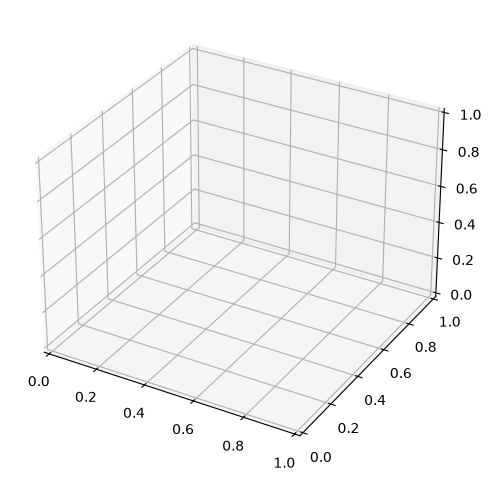

In [64]:
#Plotting results
x_test = torch.linspace(0, L, sensor_num).to(device)
t_test = torch.linspace(0, M, 50).to(device)

X, T = torch.meshgrid(x_test, t_test, indexing='ij')  # each shape [50, 50]

# Flatten and stack into a single [N, 2] tensor of (x, t) pairs
x_flat = X.reshape(-1, 1)
t_flat = T.reshape(-1, 1)
xt_grid = torch.cat([x_flat, t_flat], dim=1)

# #Make new initial condition
sin_test_ic = torch.sin(np.pi * x_test)
flat_test_ic = torch.ones(sensor_num)

#Making torch tensors into usable numpy objects
X = X.cpu().detach().numpy()
T = T.cpu().detach().numpy()

sin_test_u = deep_net(sin_test_ic, xt_grid).reshape(X.shape).cpu().detach().numpy()
flat_test_u = deep_net(flat_test_ic, xt_grid).reshape(X.shape).cpu().detach().numpy()

sin_control_u = np.sin(np.pi*X/L) * np.exp(-a * (np.pi/L)**2 * T)
y, yy, flat_control_u = solve_heat_equation(flat_test_ic, a, L, M)

# Making plots

ic_test = [sin_test_ic, sin_control_u, flat_test_ic, flat_control_u]
graph_names = ["DeepONet", "Analytical Solution", "DeepONet", "FTCS Approximation"]
# axes = [ax1, ax2, ax3, ax4]
# surfaces = [surface1, surface2, surface3, surface4]

fig = plt.figure(figsize=(13, 13))

for graph in range(0, 4):
    # axis = axes[graph]
    # surface = surfaces[graph]

    ax = fig.add_subplot(2, 2, graph+1, projection='3d')
    surface = ax.plot_surface(X, T, ic_test[graph], cmap='viridis', linewidth=0, antialiased=False)
    ax.set_xlabel('position')
    ax.set_ylabel('time')
    ax.set_title(graph_names[graph])
    fig.colorbar(surface, ax=ax, shrink=0.6)


# fig = plt.figure(figsize=(14, 6))
# ax1 = fig.add_subplot(1, 2, 1, projection='3d')

# surface1 = ax1.plot_surface(X, T, u_test, cmap='viridis', linewidth=0, antialiased=False)
# ax1.set_xlabel('position')
# ax1.set_ylabel('time')
# ax1.set_title('DeepONet')
# fig.colorbar(surface1, ax=ax1, shrink=0.6)

# ax2 = fig.add_subplot(1, 2, 2, projection='3d')

# u = np.sin(np.pi*X/L) * np.exp(-a * (np.pi/L)**2 * T)

# surface2 = ax2.plot_surface(X, T, u, cmap='viridis', linewidth=0, antialiased=False)
# ax2.set_xlabel('position')
# ax2.set_ylabel('time')
# ax2.set_title('Analytical Solution')
# fig.colorbar(surface2, ax=ax2, shrink=0.6)

#plt.tight_layout()
plt.show()


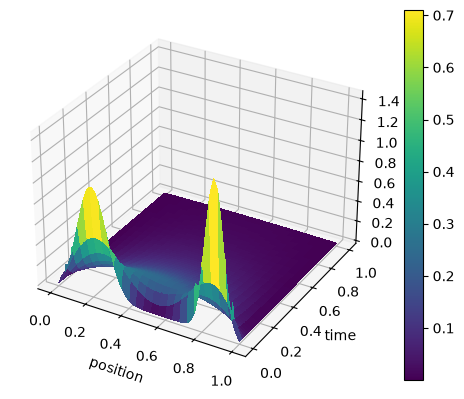

In [61]:
# Testing and graphing the numerical solver

x_test = torch.linspace(0, L, sensor_num)
ic_test = make_ic_array(L, ic_type=1)
x, t, U = solve_heat_equation(ic_test, a, L, M)

X, T = torch.meshgrid(torch.from_numpy(x), torch.from_numpy(t), indexing='ij')
# X, T = torch.meshgrid(x, t, indexing='ij')

X = X.detach().numpy()
T = T.detach().numpy()

fig = plt.figure()
ax1 = fig.add_subplot(projection='3d')

surface = ax1.plot_surface(X, T, U, cmap='viridis', linewidth=0, antialiased=False)
ax1.set_xlabel('position')
ax1.set_ylabel('time')

fig.colorbar(surface)